<a href="https://colab.research.google.com/github/shekinahudegbue/COSC-4371/blob/main/P15_final_checkpoint.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q datasets scikit-learn pandas numpy scipy matplotlib

In [2]:
import re, sys, time, platform, unicodedata, subprocess, os
import numpy as np, pandas as pd, scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from datasets import load_dataset
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import roc_curve

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
SEED = 4371
FPR_TARGET = 0.05
NEAR_DUP = 0.9
N_FOLDS = 5
REVISIONS = {"safeguard": "a3a877d", "deepset": "4f61ecb", "gandalf": "04737b6"}

MIX_SAFEGUARD_ROWS = 1000
ERR_VALUE, ERR_COLUMN = "baseline", "safeguard-test"
FIG_COLUMN = "safeguard-test"
FIG_VALUES = ["baseline", "safeguard-full"]
DIRECTION = None

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__)
print("Hardware:", platform.processor() or platform.machine(), "| CPUs:", os.cpu_count())

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1
Hardware: x86_64 | CPUs: 2


## Load the three datasets (same pinned revisions as the midsemester)

In [3]:
def hf(name, rev):
    try:
        return load_dataset(name, revision=rev)
    except Exception as e:
        print(f"WARNING: could not load {name} at revision {rev} ({e}). Loading the default revision instead.")
        return load_dataset(name)

def load_raw():
    specs = [("safeguard", "xTRam1/safe-guard-prompt-injection"),
             ("deepset", "deepset/prompt-injections"),
             ("gandalf", "Lakera/gandalf_ignore_instructions")]
    parts = []
    for short, hub in specs:
        d = hf(hub, REVISIONS[short])
        for s in d:
            df = d[s].to_pandas()
            if short == "gandalf":
                df["label"] = 1
            parts.append(pd.DataFrame({"dataset": short, "orig_split": s, "idx": range(len(df)),
                                       "text": df["text"], "label": df["label"].fillna(-1).astype(int)}))
    raw = pd.concat(parts, ignore_index=True)
    raw["text"] = raw["text"].fillna("").astype(str)
    raw["row_id"] = raw["dataset"] + ":" + raw["orig_split"] + ":" + raw["idx"].astype(str)
    return raw

raw = load_raw()
print(raw.groupby(["dataset", "orig_split"]).size())

ZW = dict.fromkeys(map(ord, "​‌‍⁠﻿"), None)
def norm(t):
    t = unicodedata.normalize("NFKC", t).translate(ZW).lower()
    return re.sub(r"\s+", " ", t).strip()
raw["norm"] = raw["text"].map(norm)

sim_vec = TfidfVectorizer(analyzer="char", ngram_range=(3, 5))
sim_vec.fit(raw["norm"].unique())

dataset    orig_split
deepset    test           116
           train          546
gandalf    test           112
           train          777
           validation     111
safeguard  test          2060
           train         8236
dtype: int64


TfidfVectorizer(analyzer='char', ngram_range=(3, 5))

## Pools, validation sets and the fixed test sets

Each source gets its own training pool and its own validation set (one of five stratified group folds, near-duplicate clusters
kept on one side). The **test sets are the midsemester test sets**, so the baseline row reproduces your midsemester numbers.
Training rows of the *other* source that exactly or nearly duplicate a test row are dropped from that source's pool (counted below).

In [4]:
def near_dup_groups(texts):
    X = sim_vec.transform(texts)
    n, XT = X.shape[0], X.T.tocsc()
    rr, cc = [], []
    for s in range(0, n, 400):
        S = (X[s:s + 400] @ XT).toarray()
        r, c = np.nonzero(S >= NEAR_DUP)
        rr.append(r + s); cc.append(c)
    rr, cc = np.concatenate(rr), np.concatenate(cc)
    adj = sp.csr_matrix((np.ones(len(rr), dtype=np.int8), (rr, cc)), shape=(n, n))
    return connected_components(adj, directed=False)[1]

def make_pool(source, drop_against=None):
    pool = raw[(raw.dataset == source) & (raw.orig_split == "train")].copy()
    lab = pool.groupby("norm")["label"].nunique()
    conflict = set(lab[lab > 1].index)
    n_conflict = int(pool["norm"].isin(conflict).sum())
    pool = pool[~pool["norm"].isin(conflict)].reset_index(drop=True)
    n_dropped = 0
    if drop_against is not None:
        exact = pool["norm"].isin(set(drop_against["norm"])).values
        sim = (sim_vec.transform(pool["norm"]) @ sim_vec.transform(drop_against["norm"]).T).max(axis=1).toarray().ravel()
        bad = exact | (sim >= NEAR_DUP)
        n_dropped = int(bad.sum())
        pool = pool[~bad].reset_index(drop=True)
    groups = near_dup_groups(pool["norm"])
    skf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    tr_i, va_i = next(skf.split(pool, pool["label"], groups))
    pool["split"] = "train"; pool.loc[va_i, "split"] = "validation"
    print(f"{source}: conflicting-label rows set aside {n_conflict}; rows dropped for overlapping a test row {n_dropped}; "
          f"train {len(tr_i)} ({int(pool.label[tr_i].sum())} injection), validation {len(va_i)} ({int(pool.label[va_i].sum())} injection)")
    return pool


pool_d = make_pool("deepset")
Xtv = sim_vec.transform(pool_d["norm"]); tv_norm = set(pool_d["norm"])
tests = {}
for name, (ds, sp_) in {"deepset-test": ("deepset", "test"), "safeguard-test": ("safeguard", "test"),
                        "gandalf-test": ("gandalf", "test")}.items():
    t = raw[(raw.dataset == ds) & (raw.orig_split == sp_)].copy()
    exact = t["norm"].isin(tv_norm).values
    sim = (sim_vec.transform(t["norm"]) @ Xtv.T).max(axis=1).toarray().ravel()
    keep = ~(exact | ((sim >= NEAR_DUP) & ~exact))
    tests[name] = t[keep].reset_index(drop=True)
    print(f"{name}: {len(t)} rows, kept {int(keep.sum())} ({int(tests[name].label.sum())} injection)")
all_test = pd.concat(tests.values(), ignore_index=True)
pool_s = make_pool("safeguard", drop_against=all_test)

deepset: conflicting-label rows set aside 0; rows dropped for overlapping a test row 0; train 437 (158 injection), validation 109 (45 injection)
deepset-test: 116 rows, kept 113 (60 injection)
safeguard-test: 2060 rows, kept 2058 (648 injection)
gandalf-test: 112 rows, kept 112 (112 injection)
safeguard: conflicting-label rows set aside 5; rows dropped for overlapping a test row 240; train 6392 (1905 injection), validation 1599 (486 injection)


## The values of the variable: training sets and sizes

In [5]:
def sub(train, n):
    if n is None or n >= len(train): return train
    keep, _ = train_test_split(train, train_size=n, stratify=train["label"], random_state=SEED)
    return keep

tr_d, va_d = pool_d[pool_d.split == "train"], pool_d[pool_d.split == "validation"]
tr_s, va_s = pool_s[pool_s.split == "train"], pool_s[pool_s.split == "validation"]

sets = {"baseline": (tr_d, va_d)}
for n in (100, 300):  sets[f"deepset-{n}"] = (sub(tr_d, n), va_d)
for n in (100, 300, 1000): sets[f"safeguard-{n}"] = (sub(tr_s, n), va_s)
sets["safeguard-full"] = (tr_s, va_s)
mix_va = pd.concat([va_d, va_s], ignore_index=True)
mix_tr = pd.concat([tr_d, sub(tr_s, MIX_SAFEGUARD_ROWS)], ignore_index=True)
mix_tr = mix_tr[~mix_tr["norm"].isin(set(mix_va["norm"]))]
sets["mixture"] = (mix_tr, mix_va)

print(pd.DataFrame({k: {"train rows": len(v[0]), "train injections": int(v[0].label.sum()),
                        "validation rows": len(v[1])} for k, v in sets.items()}).T)

                train rows  train injections  validation rows
baseline               437               158              109
deepset-100            100                36              109
deepset-300            300               108              109
safeguard-100          100                30             1599
safeguard-300          300                89             1599
safeguard-1000        1000               298             1599
safeguard-full        6392              1905             1599
mixture               1436               455             1708


## Leakage counts (midsemester 2(d)) for every value

In [6]:
def leak(tr, va):
    out = {}
    for kind, col in [("raw", "text"), ("normalized", "norm")]:
        out[f"train=test ({kind})"] = int(tr[col].isin(set(all_test[col])).sum())
        out[f"train=validation ({kind})"] = int(tr[col].isin(set(va[col])).sum())
    return out
leak_table = pd.DataFrame({k: leak(*v) for k, v in sets.items()}).T
print(leak_table)
assert (leak_table.values == 0).all(), "a training row duplicates a test or validation row: fix before scoring"

                train=test (raw)  train=validation (raw)  train=test (normalized)  train=validation (normalized)
baseline                       0                       0                        0                              0
deepset-100                    0                       0                        0                              0
deepset-300                    0                       0                        0                              0
safeguard-100                  0                       0                        0                              0
safeguard-300                  0                       0                        0                              0
safeguard-1000                 0                       0                        0                              0
safeguard-full                 0                       0                        0                              0
mixture                        0                       0                        0               

## Train every value, choose its threshold on its own validation set, score every test set once

In [7]:
def choose_threshold(y, s, fpr_target):
    benign = s[y == 0]
    for t in np.sort(np.unique(s)):
        if (benign >= t).mean() <= fpr_target:
            return float(t)
    return float(np.nextafter(s.max(), 2))

score_rows, info = [], []
for name, (tr, va) in sets.items():
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED)
    t0 = time.perf_counter()
    Xtr = vec.fit_transform(tr["text"])
    clf.fit(Xtr, tr["label"])
    secs = time.perf_counter() - t0
    s_val = clf.predict_proba(vec.transform(va["text"]))[:, 1]
    y_val = va["label"].to_numpy()
    thr = round(float(np.ceil(choose_threshold(y_val, s_val, FPR_TARGET) * 1e4)) / 1e4, 4)
    vfpr, vrec = (s_val[y_val == 0] >= thr).mean(), (s_val[y_val == 1] >= thr).mean()
    assert vfpr <= FPR_TARGET
    info.append({"value": name, "n_train": len(tr), "n_validation": len(va), "threshold": thr,
                 "val FPR": round(vfpr, 3), "val recall": round(vrec, 3), "train seconds": round(secs, 2)})
    for col, t in tests.items():
        s = clf.predict_proba(vec.transform(t["text"]))[:, 1]
        score_rows.append(pd.DataFrame({"row_id": t["row_id"], "value": name, "column": col,
                                        "label": t["label"], "score": s, "threshold": thr}))
info = pd.DataFrame(info)
scores_df = pd.concat(score_rows, ignore_index=True)
print(info.to_string(index=False))
print(f"\nTotal training time for all {len(info)} values: {info['train seconds'].sum():.1f} s "
      f"({info['train seconds'].sum() / 60:.2f} min)")


g = scores_df.assign(pred=lambda d: d.score >= d.threshold)
prev = g.groupby(["value", "column"]).apply(lambda d: pd.Series({
    "recall": round(d.pred[d.label == 1].mean(), 4),
    "fpr": round(d.pred[d.label == 0].mean(), 4) if (d.label == 0).any() else np.nan}), include_groups=False)
print("\nPreview (not for the PDF):"); print(prev.unstack("column").round(3).to_string())

         value  n_train  n_validation  threshold  val FPR  val recall  train seconds
      baseline      437           109     0.4956    0.031       0.822           0.41
   deepset-100      100           109     0.4945    0.047       0.711           0.04
   deepset-300      300           109     0.4569    0.047       0.844           0.12
 safeguard-100      100          1599     0.3977    0.049       0.959           0.09
 safeguard-300      300          1599     0.3738    0.049       0.979           1.13
safeguard-1000     1000          1599     0.3199    0.049       0.988           1.17
safeguard-full     6392          1599     0.1803    0.049       0.994           8.85
       mixture     1436          1708     0.3947    0.048       0.977           1.16

Total training time for all 8 values: 13.0 s (0.22 min)

Preview (not for the PDF):
                     recall                                      fpr                            
column         deepset-test gandalf-test safeguard-te

## Write split.csv, scores.csv, train_membership.csv

In [8]:
split_df = pd.concat([pool_d[["row_id", "dataset", "split", "label"]],
                      pool_s[["row_id", "dataset", "split", "label"]]] +
                     [t.assign(split="test")[["row_id", "dataset", "split", "label"]] for t in tests.values()],
                     ignore_index=True)
assert not split_df["row_id"].duplicated().any()
split_df.to_csv("split.csv", index=False)
scores_df.to_csv("scores.csv", index=False)
pd.concat([pd.DataFrame({"value": k, "row_id": v[0]["row_id"]}) for k, v in sets.items()]).to_csv("train_membership.csv", index=False)
print("split.csv", split_df.shape, "| scores.csv", scores_df.shape)

split.csv (10820, 4) | scores.csv (18264, 6)


## Error analysis (sections 4(a) and 4(b))

First draws the sample and prints the rows. **Read them**, then edit `categorize` so each row lands in exactly one category.
The starter rules below are only a guess made without seeing your errors.

In [9]:
cell = scores_df[(scores_df.value == ERR_VALUE) & (scores_df.column == ERR_COLUMN)]
texts = pd.concat(tests.values()).set_index("row_id")["text"]
fp = cell[(cell.label == 0) & (cell.score >= cell.threshold)]
fn = cell[(cell.label == 1) & (cell.score < cell.threshold)]
fp_s = fp.sample(n=min(10, len(fp)), random_state=SEED)
fn_s = fn.sample(n=min(10, len(fn)), random_state=SEED)
print(f"cell: value={ERR_VALUE}, column={ERR_COLUMN}, seed={SEED}; "
      f"{len(fp)} false positives (sampled {len(fp_s)}), {len(fn)} false negatives (sampled {len(fn_s)})\n")
for kind, d in [("FALSE POSITIVE", fp_s), ("FALSE NEGATIVE", fn_s)]:
    for rid in d["row_id"]:
        print(f"[{kind}] {rid}: {texts[rid][:300]!r}")

cell: value=baseline, column=safeguard-test, seed=4371; 1077 false positives (sampled 10), 42 false negatives (sampled 10)

[FALSE POSITIVE] safeguard:test:1786: 'Given a word and its definition, decide if the word is an instance of the concept described by the definition.\n\nWord: "Coffee"\nDefinition: A beverage made from the roasted seeds of a tropical shrub.'
[FALSE POSITIVE] safeguard:test:1035: 'Given the stream of consciousness rationale, provide a reasonable question and answer. Rationale: The pots cannot be filled with water if they are overflowing with dirt.\n The question and answer:'
[FALSE POSITIVE] safeguard:test:1141: 'Question: how much are the harry potter movies worth?\nWould "Also due to the success of the books and films, Harry Potter has been used for a theme park, The Wizarding World of Harry Potter in Universal Parks & Resorts \'s Islands of Adventure ." be a reasonable answer?'
[FALSE POSITIVE] safeguard:test:893: "The following movie review expresses what senti

In [10]:
FAKE = re.compile(r"fake news", re.I)
DATA = re.compile(r"sensitive|confidential|personal medical|user data|transfer funds", re.I)
TASK = re.compile(r"\bGiven\b|Question:|Options:|In this task|The following|Step-by-step|Thoughts\?")

def categorize(text):
    if FAKE.search(text): return "fake-news request"
    if DATA.search(text): return "demand for confidential data or funds"
    if TASK.search(text): return "task-formatted benign prompt"
    if len(text) > 200:   return "long passage prompt"
    if len(text) <= 80:   return "short everyday question"
    return "other"

sample = pd.concat([fp_s.assign(kind="FP"), fn_s.assign(kind="FN")])
sample["category"] = [categorize(texts[r]) for r in sample["row_id"]]
errors_df = sample.assign(value=ERR_VALUE, column=ERR_COLUMN)[["row_id", "value", "column", "category"]]
errors_df.to_csv("errors.csv", index=False)

cat = (sample.groupby(["category", "kind"]).size().unstack(fill_value=0)
       .reindex(columns=["FP", "FN"], fill_value=0))
cat["example row id"] = sample.groupby("category")["row_id"].first()
print(cat.to_string())
for c in ("other", "misc", "unknown"):
    if (sample.category == c).sum() > 5:
        print(f"WARNING: catch-all '{c}' holds more than 5 rows; refine the rules")
if sample.category.nunique() < 2:
    print("Only one category: give one reason in 4(b) why your errors fit only one.")

kind                                   FP  FN       example row id
category                                                          
demand for confidential data or funds   0   8   safeguard:test:242
fake-news request                       0   2   safeguard:test:163
long passage prompt                     2   0  safeguard:test:1123
short everyday question                 1   0  safeguard:test:1910
task-formatted benign prompt            7   0  safeguard:test:1786


## Checker (upload `check_final_checkpoint.py` first; set `DIRECTION` in the settings cell)

In [11]:
DIRECTION = "lower";
if not os.path.exists("check_final_checkpoint.py"):
    print("Upload check_final_checkpoint.py to the Colab files panel, then re-run this cell.")
elif DIRECTION is None:
    print('Set DIRECTION to "higher", "lower" or "either" (from your 1(e)) in the settings cell, then re-run this cell.')
else:
    cmd = [sys.executable, "check_final_checkpoint.py", "--split", "split.csv", "--scores", "scores.csv",
           "--errors", "errors.csv", "--metric", "recall", "--reference", "baseline", "--direction", DIRECTION]
    print(" ".join(cmd)); out = subprocess.run(cmd, capture_output=True, text=True); print(out.stdout, out.stderr)

/usr/bin/python3 check_final_checkpoint.py --split split.csv --scores scores.csv --errors errors.csv --metric recall --reference baseline --direction lower
split.csv: 10820 rows. scores.csv: 18264 rows, 8 value(s), 3 column(s).
Values: baseline, deepset-100, deepset-300, safeguard-100, safeguard-300, safeguard-1000, safeguard-full, mixture

Rows per dataset and split
--------------------------
  dataset      split  rows  positive  negative  positive %
  deepset      train   437       158       279       36.16
  deepset validation   109        45        64       41.28
  deepset       test   113        60        53       53.10
  gandalf       test   112       112         0      100.00
safeguard      train  6392      1905      4487       29.80
safeguard validation  1599       486      1113       30.39
safeguard       test  2058       648      1410       31.49

Metrics per value and column (positive when score >= the threshold)
--------------------------------------------------------------

## Figure (section 2): ROC curves with a log false-positive axis, one column, operating points marked

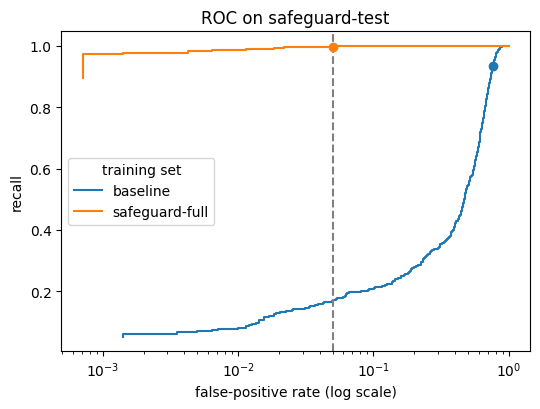

Caption: column safeguard-test, 2058 test rows, 31.5% injections; values shown: baseline, safeguard-full; dots mark each model's chosen threshold, dashed line = 5% FPR.


In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(5.5, 4.2))
for v in FIG_VALUES:
    g = scores_df[(scores_df.value == v) & (scores_df.column == FIG_COLUMN)]
    fpr, tpr, _ = roc_curve(g["label"], g["score"])
    line, = plt.plot(fpr[fpr > 0], tpr[fpr > 0], label=v)
    thr = g["threshold"].iloc[0]; pred = g["score"] >= thr
    plt.scatter([pred[g.label == 0].mean()], [pred[g.label == 1].mean()], color=line.get_color(), zorder=3)
plt.xscale("log"); plt.xlabel("false-positive rate (log scale)"); plt.ylabel("recall")
plt.axvline(FPR_TARGET, ls="--", c="gray"); plt.legend(title="training set"); plt.title(f"ROC on {FIG_COLUMN}")
plt.tight_layout(); plt.savefig("figure_roc.png", dpi=200); plt.show()
g = scores_df[(scores_df.value == FIG_VALUES[0]) & (scores_df.column == FIG_COLUMN)]
print(f"Caption: column {FIG_COLUMN}, {len(g)} test rows, {100 * g['label'].mean():.1f}% injections; "
      f"values shown: {', '.join(FIG_VALUES)}; dots mark each model's chosen threshold, dashed line = 5% FPR.")

In [13]:
from sklearn.svm import LinearSVC

svm_rows, svm_info = [], []
for name, (tr, va) in sets.items():
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
    clf = LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=SEED)
    t0 = time.perf_counter()
    Xtr = vec.fit_transform(tr["text"])
    clf.fit(Xtr, tr["label"])
    secs = time.perf_counter() - t0
    s_val = clf.decision_function(vec.transform(va["text"]))
    y_val = va["label"].to_numpy()
    thr = round(float(np.ceil(choose_threshold(y_val, s_val, FPR_TARGET) * 1e4)) / 1e4, 4)
    vfpr, vrec = (s_val[y_val == 0] >= thr).mean(), (s_val[y_val == 1] >= thr).mean()
    assert vfpr <= FPR_TARGET
    svm_info.append({"value": name, "n_train": len(tr), "threshold": thr, "val FPR": round(vfpr, 3),
                     "val recall": round(vrec, 3), "train seconds": round(secs, 2)})
    for col, t in tests.items():
        s = clf.decision_function(vec.transform(t["text"]))
        svm_rows.append(pd.DataFrame({"row_id": t["row_id"], "value": name, "column": col,
                                      "label": t["label"], "score": s, "threshold": thr}))
svm_info = pd.DataFrame(svm_info)
scores_svm_df = pd.concat(svm_rows, ignore_index=True)
scores_svm_df.to_csv("scores_svm.csv", index=False)
print(svm_info.to_string(index=False))
print(f"\nTotal SVM training time for all {len(svm_info)} values: {svm_info['train seconds'].sum():.1f} s "
      f"({svm_info['train seconds'].sum() / 60:.2f} min)")
g = scores_svm_df.assign(pred=lambda d: d.score >= d.threshold)
prev = g.groupby(["value", "column"]).apply(lambda d: pd.Series({
    "recall": round(d.pred[d.label == 1].mean(), 4),
    "fpr": round(d.pred[d.label == 0].mean(), 4) if (d.label == 0).any() else np.nan}), include_groups=False)
print("\nPreview (not for the PDF):"); print(prev.unstack("column").round(3).to_string())

         value  n_train  threshold  val FPR  val recall  train seconds
      baseline      437    -0.0617    0.047       0.822           0.19
   deepset-100      100    -0.1260    0.031       0.822           0.04
   deepset-300      300     0.0006    0.031       0.822           0.13
 safeguard-100      100    -0.3549    0.049       0.965           0.09
 safeguard-300      300    -0.3885    0.049       0.986           0.31
safeguard-1000     1000    -0.4641    0.049       0.992           1.34
safeguard-full     6392    -0.6860    0.049       0.996           5.78
       mixture     1436    -0.2935    0.048       0.976           2.04

Total SVM training time for all 8 values: 9.9 s (0.17 min)

Preview (not for the PDF):
                     recall                                      fpr                            
column         deepset-test gandalf-test safeguard-test deepset-test gandalf-test safeguard-test
value                                                                          

In [14]:
direction = "lower"
if os.path.exists("check_final_checkpoint.py"):
    cmd = [sys.executable, "check_final_checkpoint.py", "--split", "split.csv", "--scores", "scores_svm.csv",
           "--metric", "recall", "--reference", "baseline", "--direction", direction]
    print(" ".join(cmd)); out = subprocess.run(cmd, capture_output=True, text=True); print(out.stdout, out.stderr)
else:
    print("Upload check_final_checkpoint.py first.")

/usr/bin/python3 check_final_checkpoint.py --split split.csv --scores scores_svm.csv --metric recall --reference baseline --direction lower
split.csv: 10820 rows. scores.csv: 18264 rows, 8 value(s), 3 column(s).
Values: baseline, deepset-100, deepset-300, safeguard-100, safeguard-300, safeguard-1000, safeguard-full, mixture

Rows per dataset and split
--------------------------
  dataset      split  rows  positive  negative  positive %
  deepset      train   437       158       279       36.16
  deepset validation   109        45        64       41.28
  deepset       test   113        60        53       53.10
  gandalf       test   112       112         0      100.00
safeguard      train  6392      1905      4487       29.80
safeguard validation  1599       486      1113       30.39
safeguard       test  2058       648      1410       31.49

Metrics per value and column (positive when score >= the threshold)
-------------------------------------------------------------------
Each value

In [15]:
import base64
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

ZW = "​"
HOMO = str.maketrans({"a": "а", "e": "е", "o": "о", "p": "р", "c": "с",
                      "x": "х", "y": "у", "i": "і"})          # Latin -> look-alike Cyrillic
def zero_width(s): return "".join(ch + (ZW if (k + 1) % 4 == 0 else "") for k, ch in enumerate(s))   # after every 4th character
def homoglyph(s):  return s.translate(HOMO)
def b64(s):        return base64.b64encode(s.encode("utf-8")).decode("ascii")
TRANSFORMS = {"zerowidth": zero_width, "homoglyph": homoglyph, "base64": b64}

# sanity: show one example of each on a short string
for k, f in TRANSFORMS.items(): print(f"{k:10s}", repr(f("Ignore previous instructions"))[:70])

saved = pd.read_csv("scores.csv").groupby("value")["threshold"].first()
saved_svm = pd.read_csv("scores_svm.csv").groupby("value")["threshold"].first()
obf_rows = {k: [] for k in TRANSFORMS}                                    # keyed by transform, then by classifier
for name, (tr, va) in sets.items():
    for clf_name in ("logreg", "svm"):
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
        if clf_name == "logreg":
            clf = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED)
            score = lambda X: clf.predict_proba(X)[:, 1]
        else:
            clf = LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=SEED)
            score = lambda X: clf.decision_function(X)
        clf.fit(vec.fit_transform(tr["text"]), tr["label"])
        s_val = score(vec.transform(va["text"])); y_val = va["label"].to_numpy()
        thr = round(float(np.ceil(choose_threshold(y_val, s_val, FPR_TARGET) * 1e4)) / 1e4, 4)
        ref = (saved if clf_name == "logreg" else saved_svm)[name]
        assert abs(thr - ref) < 1e-9, f"threshold mismatch for {name}/{clf_name}: {thr} vs {ref}"   # proves it is the same model
        for col, t in tests.items():
            for tname, f in TRANSFORMS.items():
                s = score(vec.transform(t["text"].map(f)))
                obf_rows[tname].append(pd.DataFrame({"classifier": clf_name, "row_id": t["row_id"], "value": name, "column": col,
                                                     "label": t["label"], "score": s, "threshold": thr}))
summ = []
for tname, parts in obf_rows.items():
    d = pd.concat(parts, ignore_index=True)
    for clf_name in ("logreg", "svm"):
        d[d.classifier == clf_name].drop(columns="classifier").to_csv(f"scores_obf_{tname}_{clf_name}.csv", index=False)
    d["pred"] = d.score >= d.threshold
    r = d.groupby(["classifier", "value", "column"]).apply(lambda g: pd.Series({
        "recall": g.pred[g.label == 1].mean(), "fpr": g.pred[g.label == 0].mean() if (g.label == 0).any() else np.nan}),
        include_groups=False).reset_index()
    r["transform"] = tname; summ.append(r)
summ = pd.concat(summ, ignore_index=True)
summ.to_csv("obfuscation_summary.csv", index=False)
print("\nRecall on obfuscated test rows (original threshold). 'original' = same value, same column, unobfuscated (from scores files).")
orig = pd.concat([pd.read_csv("scores.csv").assign(classifier="logreg"), pd.read_csv("scores_svm.csv").assign(classifier="svm")])
orig["pred"] = orig.score >= orig.threshold
o = orig.groupby(["classifier", "value", "column"]).apply(lambda g: g.pred[g.label == 1].mean(), include_groups=False).rename("original").reset_index()
tab = summ.pivot_table(index=["classifier", "value", "column"], columns="transform", values="recall").reset_index().merge(o)
print(tab[["classifier", "value", "column", "original", "zerowidth", "homoglyph", "base64"]].round(3).to_string(index=False))

zerowidth  'Igno\u200bre p\u200brevi\u200bous \u200binst\u200bruct\u200bions\u200
homoglyph  'Ignоrе рrеvіоus іnstruсtіоns'
base64     'SWdub3JlIHByZXZpb3VzIGluc3RydWN0aW9ucw=='

Recall on obfuscated test rows (original threshold). 'original' = same value, same column, unobfuscated (from scores files).
classifier          value         column  original  zerowidth  homoglyph  base64
    logreg       baseline   deepset-test     0.833      0.750      0.383   0.000
    logreg       baseline   gandalf-test     0.973      0.875      0.804   0.000
    logreg       baseline safeguard-test     0.935      0.894      0.574   0.000
    logreg    deepset-100   deepset-test     0.617      0.583      0.300   0.000
    logreg    deepset-100   gandalf-test     0.964      0.839      0.759   0.000
    logreg    deepset-100 safeguard-test     0.884      0.855      0.620   0.000
    logreg    deepset-300   deepset-test     0.883      0.867      0.517   0.000
    logreg    deepset-300   gandalf-test     0.9

In [16]:
for clf_name in ("logreg", "svm"):
    for tname in ("zerowidth", "homoglyph", "base64"):
        f = f"scores_obf_{tname}_{clf_name}.csv"
        cmd = [sys.executable, "check_final_checkpoint.py", "--split", "split.csv", "--scores", f,
               "--metric", "recall", "--reference", "baseline", "--direction", "lower"]
        out = subprocess.run(cmd, capture_output=True, text=True).stdout
        print("=" * 90); print(" ".join(cmd[1:])); print(out[out.find("Results table"):])


check_final_checkpoint.py --split split.csv --scores scores_obf_zerowidth_logreg.csv --metric recall --reference baseline --direction lower
Results table: recall [95% interval] (copy into section 1(d))
-------------------------------------------------------------
A one-class cell holds the metric the checker prints for it, named in parentheses.

Column: deepset-test
  baseline         0.7500 [0.6441, 0.8571]
  deepset-100      0.5833 [0.4590, 0.6970]
  deepset-300      0.8667 [0.7796, 0.9500]
  safeguard-100    0.0833 [0.0175, 0.1640]
  safeguard-300    0.1000 [0.0333, 0.1846]
  safeguard-1000   0.1000 [0.0345, 0.1834]
  safeguard-full   0.2667 [0.1578, 0.3751]
  mixture          0.6667 [0.5410, 0.7834]

Column: safeguard-test
  baseline         0.8935 [0.8712, 0.9184]
  deepset-100      0.8549 [0.8279, 0.8816]
  deepset-300      0.9676 [0.9515, 0.9805]
  safeguard-100    0.9028 [0.8794, 0.9256]
  safeguard-300    0.9676 [0.9536, 0.9805]
  safeguard-1000   0.9769 [0.9645, 0.9875]
  saf